## Read the train/test data

In [1]:
import collections

import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/length_dependent_hmm/peptide_cores' # work laptop
APPROACH = "DECOY_PATHS"

In [2]:
data_df = pd.read_csv(f"{DATA_PATH}/extractd_cores.csv", index_col=0, sep=';')


In [3]:
ALLELES = list(data_df['allele'].unique())
selected_alleles = ALLELES
models_to_read = ['v']
TARGET_LENGTHS = list(data_df.core_peptide.str.len().unique())

## Also add immunogenic data

In [16]:
# from os import listdir
# from os.path import isfile, join
# from mhcnames import normalize_allele_name
# DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/' # windows
#
# onlyfiles = [f for f in listdir(DATA_PATH) if isfile(join(DATA_PATH, f))]
# IMM_ALLELES = []
# per_allele_imm_df = dict()
# for file_name in onlyfiles:
#     allele_name = file_name.split("_", 1)[1].split('.')[0]
#     allele_name = normalize_allele_name(allele_name)
#     per_allele_imm_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
#     IMM_ALLELES.append(allele_name)
# IMM_ALLELES

In [17]:
from data_reading_methods import get_available_alleles, read_data
# DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows
#
# def merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders, per_allele_imm_data):
#     for allele in ALLELES:
#         if allele in IMM_ALLELES:
#             new_allele = allele + "_imm"
#
#             per_allele_per_kfold_per_length_binders[new_allele] = dict()
#             # per_length_peptides = defaultdict(list)
#
#             # for kfold, per_length_imm_peptides in per_allele_per_kfold_per_length_imm[allele].items():
#             #     for target_length, peptides in per_length_imm_peptides.items():
#             #         per_length_peptides[target_length].extend(peptides)
#             for kfold, per_length_peptides in per_allele_per_kfold_per_length_binders[allele].items():
#                 per_allele_per_kfold_per_length_binders[new_allele][kfold] = dict()
#                 for target_length in per_length_peptides.keys():
#                     imm_df = per_allele_imm_data[allele]
#                     imm_df = imm_df[imm_df['immunogenic'] == 1]
#                     imm_df = imm_df[imm_df['length'] == target_length]
#                     per_allele_per_kfold_per_length_binders[new_allele][kfold][target_length] = imm_df['peptide'].values
#
# merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_train, per_allele_imm_df)
# merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_test, per_allele_imm_df)


# Read models

In [4]:
## PARAMETERS
RUNS = 15
# RUNS = 1
TOTAL_SPLITS = 1
SELECTED_RUN = 0
SELECTED_RUN = set(np.arange(0, RUNS))
# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
MODELS_DESCRIPTIONS = {
    "viterbi_simple_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": 7,
        "core_end_state": 8

    },
    "viterbi_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": 35,
        "core_end_state": 36,
        "need_to_delete": [37, 38]

    },
    "viterbi_with_pseudo_and_weights_7_reconstructed": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo-reconstructed/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": 35,
        "core_end_state": 36,
        "need_to_delete": [37, 38]

    },
        "viterbi_with_pseudo_and_weights_7_retrained": {
        "path": "experiment_results/retrained_models/",
        "states": 30,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [9],
        "core_start_state": None,
        "core_end_state": None,
        "need_to_delete": []

    },
    "viterbi_with_pseudo_and_weights_7_retrained_smaller_model": {
        "path": "experiment_results/retrained_models/",
        "states": 20,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [9],
        "core_start_state": None,
        "core_end_state": None,
        "need_to_delete": []

    },
    "viterbi_multiple_7_retrained": {
        "path": "experiment_results/retrained_models/",
        "states": 20,
        "params_string": "30-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-DRB1*01:01',
                    'HLA-DPA1*01:03/DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [9],
        "core_start_state": None,
        "core_end_state": None,
        "need_to_delete": []

    }
}

In [5]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['viterbi_simple_with_pseudo_and_weights_7', 'viterbi_with_pseudo_and_weights_7', 'viterbi_with_pseudo_and_weights_7_reconstructed', 'viterbi_with_pseudo_and_weights_7_retrained', 'viterbi_with_pseudo_and_weights_7_retrained_smaller_model', 'viterbi_multiple_7_retrained'])

In [6]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
    #     "single_allele_balanced_class2_joiners",
    # "single_allele_with_cycle_base_model",
    #  "anchor_model_5_single_allele_balanced_data_attempt3",
    'viterbi_multiple_7_retrained'
    # 'multiple_allele_balanced_longer_training'
]


In [7]:
from hmm_logic_methods import load_model

In [9]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_models = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_models[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [10]:
list(per_name_models.keys())

['0_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '1_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '2_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '3_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '4_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '5_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '6_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '7_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '10_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DR

## Select run and split

In [11]:
for model_key in list(per_name_models.keys()):
    if name_to_split[model_key] != SELECTED_SPLIT:
        del per_name_models[model_key]
    elif type(SELECTED_RUN) == set:
        if name_to_run[model_key] not in SELECTED_RUN:
            del per_name_models[model_key]
    elif name_to_run[model_key] != SELECTED_RUN:
        del per_name_models[model_key]
per_name_models = dict(reversed(sorted(per_name_models.items(), key=lambda item: item[0])))

In [12]:
list(per_name_models.keys())

['9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '7_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '6_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '5_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '4_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '3_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '2_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '1_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '14_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0',
 '13_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_D

# Populate path embeddings for all models
Here we have already read our models and train/test data.
Now we want to extract representaion of our data for selected models. 



In [13]:
#Params
TOP = 1000
global_selected_alleles = ALLELES # Data alleles we selected (but the number will be reduced by acceptable alleles)

# imm_global_selected_alleles = [allele_name + "_imm"  for allele_name in global_selected_alleles if allele_name not in {'HLA-DRB1*01:01','HLA-DPA1*01:03-DPB1*04:01'}]
total_selected_alleles =global_selected_alleles \
                        # + imm_global_selected_alleles

In [14]:
total_selected_alleles

['HLA-DPA1*01:03/DPB1*04:01', 'HLA-DRB1*01:01']

## Merge train data together (Take unique peptides from each allele) (will change to outside dataframe in the future)
* Handle intersections (remove for now)
* Take equal portions for each length and allele (for visualization purposes)

## Read pre-saved random paths from model

In [15]:
# exctract paths
PATHS_DF_TYPE = "SAMPLE"

if PATHS_DF_TYPE == "SAMPLE":
    paths_df_file_name = "random_paths_df.csv"
elif PATHS_DF_TYPE == "DECOY":
    paths_df_file_name = "viterbi_paths_df.csv"
else:
    raise Exception("wrong type of paths df")


per_model_random_paths= dict()
for model_key, model in per_name_models.items():
    print(model_key)
    TARGET_LENGTHS = name_to_target_lengths[model_key]
    TARGET_PATH_TO_FILES = name_to_model_root[model.name] + model.name
    if PATHS_DF_TYPE == 'SAMPLE':
        paths_df = pd.read_csv("{}/{}".format(TARGET_PATH_TO_FILES, paths_df_file_name),sep=";", index_col=0)
    else:
        paths_df = pd.read_csv("{}/{}".format(TARGET_PATH_TO_FILES, paths_df_file_name),sep=";", index_col=None)

    per_model_random_paths[model_key] = paths_df

9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
7_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
6_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
5_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
4_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
3_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
2_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
1_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
14_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
13_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
12_run-9-20-st-viterbi-alg-30-

In [16]:
paths_df

,path,norm_tr_prob,len,norm_viterbi_prob,norm_bw_prob,peptide_cnt
0,grouped_model-start>s000>s005>s012>s015>s018>s...,-1.104988,7,-2.820722,-2.818170,24
1,grouped_model-start>s003>s005>s014>s017>s019>g...,-1.795362,5,-2.895935,-2.893116,7
2,grouped_model-start>s000>s009>s010>s015>s016>s...,-1.174837,15,-3.175732,-3.160474,1
3,grouped_model-start>s000>s009>s014>s015>s016>s...,-1.386232,7,-2.870865,-2.842072,4
4,grouped_model-start>s000>s006>s012>s017>s016>s...,-1.200478,7,-2.700846,-2.698998,16
...,...,...,...,...,...,...
23654,grouped_model-start>s003>s007>s012>s015>s019>s...,-1.137564,35,-3.000901,-3.000015,1
23655,grouped_model-start>s002>s009>s011>s015>s018>s...,-1.402392,11,-3.334217,-3.330026,1
23656,grouped_model-start>s000>s008>s010>s017>s018>s...,-1.280906,13,-2.942824,-2.941472,1
23657,grouped_model-start>s002>s006>s012>s015>s019>s...,-1.239361,15,-3.272929,-3.269693,1


# Calculate paths embeddings (01.05.2022)

In [17]:
from hmm_logic_methods import  get_model_representation

# Get top paths
def save_embeddingds(embedding, model, type_of_data='train'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model.name] + model.name
    assert embedding['allele'].isnull().sum() == 0
    embedding.to_csv("{}/{}_embedding.csv".format(TARGET_PATH_TO_FILES, type_of_data),sep=";", index=True)

In [18]:
RESTRICT_LENGTH = True
RESTRICTED_LENGTH = 9
SHOULD_SAMPLE = False
SAMPLE_CONSTANT = 1000

In [19]:
TOP = 1000

In [20]:
data_df

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
HPSQRLESVSFNQTGPYN,HLA-DPA1*01:03/DPB1*04:01,[ 0. 0. 0. 0. 6. 15.02 15.02 15....,HPSQRLESVSFNQTGPYN,5,13,9,18,LESVSFNQT,[15.02 15.02 15.02 15.02 15.02 15.02 15.02 15....
FEAAVYTLAKTPLIADV,HLA-DRB1*01:01,[ 0. 0. 1.04 1.04 6.2 15.31 15.31 15....,FEAAVYTLAKTPLIADV,5,13,9,17,YTLAKTPLI,[15.31 15.31 15.31 15.31 15.31 15.31 14.27 14....
PDTKKDEAIEIGLK,HLA-DRB1*01:01,[ 0. 4.18 15.33 15.33 15.33 15.33 15.33 15....,PDTKKDEAIEIGLK,2,10,9,14,TKKDEAIEI,[15.33 15.33 15.33 15.33 15.33 15.33 15.33 15....
TGQEMNVAQFLMHMG,HLA-DPA1*01:03/DPB1*04:01,[ 0. 0. 0. 6. 15.04 15.04 15.04 15....,TGQEMNVAQFLMHMG,4,12,9,15,MNVAQFLMH,[15.04 15.04 15.04 15.04 15.04 15.04 15.04 15....
LAPLASSRFLHDHQA,HLA-DPA1*01:03/DPB1*04:01,[ 0. 0. 6.01 15.06 15.06 15.06 15.06 15....,LAPLASSRFLHDHQA,3,11,9,15,LASSRFLHD,[15.06 15.06 15.06 15.06 15.06 15.06 15.06 15....
...,...,...,...,...,...,...,...,...,...
SGHWQSIDFKQV,HLA-DPA1*01:03/DPB1*04:01,[ 0. 0. 7.04 15.04 15.04 15.04 15.04 15....,SGHWQSIDFKQV,3,11,9,12,WQSIDFKQV,[15.04 15.04 15.04 15.04 15.04 15.04 15.04 15....
NTDPYQLMNAVNTLDR,HLA-DRB1*01:01,[ 0. 0. 0. 6.05 15.06 15.06 15.06 15....,NTDPYQLMNAVNTLDR,4,12,9,16,YQLMNAVNT,[15.06 15.06 15.06 15.06 15.06 15.06 15.06 15....
APIIGEYAGEVLRFVGG,HLA-DPA1*01:03/DPB1*04:01,[ 0. 6.1 15.31 15.31 15.31 15.31 15.31 15....,APIIGEYAGEVLRFVGG,2,10,9,17,IIGEYAGEV,[15.31 15.31 15.31 15.31 15.31 15.31 15.31 15....
RVEYHFLSPYVSPKESP,HLA-DRB1*01:01,[ 0. 0. 6.01 15.01 15.01 15.01 15.01 15....,RVEYHFLSPYVSPKESP,3,11,9,17,YHFLSPYVS,[15.01 15.01 15.01 15.01 15.01 15.01 15.01 15....


In [21]:
data_df = data_df.drop_duplicates('core_peptide', keep='first')

In [22]:
%%time
for model_key, model in per_name_models.items():
    print("New model key here: ", model_key)
    df_paths = per_model_random_paths[model_key]
    #preparation. Read predefined paths df
    ## Old for whole sequence
    # df_paths = load_paths_df(model)
    # if RESTRICT_LENGTH:
    #     df_paths = df_paths[df_paths['len'] == RESTRICTED_LENGTH]
    # if SHOULD_SAMPLE and len(df_paths) > SAMPLE_CONSTANT:
    #     print(f"Sampling of {SAMPLE_CONSTANT} paths")
    #     df_paths = df_paths.sample(n=SAMPLE_CONSTANT)
    #
    #
    # # calculate embeddings and save to files
    # selected_alleles = list(set(name_to_acceptable_alleles[model_key]).intersection(set(global_selected_alleles)))
    # selected_alleles = selected_alleles + [imm_item for item, imm_item in zip(global_selected_alleles, imm_global_selected_alleles) if item in selected_alleles]
    # print(f"Alleles this model can process: {selected_alleles}")
    # print("Train")
    # print(f"\tJoin allele sets")
    # peptide_set = set().union(*[allele_set
    #                          for allele_name, allele_set in per_allele_peptide_train_sets.items()
    #                          if allele_name in selected_alleles])

    if RESTRICT_LENGTH:
        df_paths = df_paths[df_paths['len'] == RESTRICTED_LENGTH]
    if SHOULD_SAMPLE and len(df_paths) > SAMPLE_CONSTANT:
        print(f"Sampling of {SAMPLE_CONSTANT} paths")
        df_paths = df_paths.sample(n=SAMPLE_CONSTANT)
    peptides = data_df['core_peptide'].values

    print(f"\tEmbedding will be calculated for {len(peptides)} points")
    print(f"\tPaths number for this model is {len(df_paths)}")
    train_repr_df, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model, peptides, paths_df=df_paths, edge_value="log_probability", top_paths=TOP, precision=3)

    #
    # for allele_name in selected_alleles:
    #     peptide_set = per_allele_peptide_train_sets[allele_name]
    #
    #     train_repr_df.loc[peptide_set, 'allele'] = allele_name
    train_repr_df = train_repr_df.merge(data_df[['core_peptide', 'allele']], left_index=True, right_on='core_peptide', validate='1:1')
    train_repr_df = train_repr_df.set_index('core_peptide')
    train_repr_df['peptide'] = train_repr_df.index.values
    # train_repr_df['allele'] = total_df.allele.values
    # train_repr_df['peptide'] = total_df.core_peptide.values
    save_embeddingds(train_repr_df, model, 'train')
    
    
    #
    # print("Test")
    # print(f"\tJoin allele sets")
    # peptide_set = set().union(*[allele_set
    #                          for allele_name, allele_set in per_allele_peptide_test_sets.items()
    #                          if allele_name in selected_alleles])
    # print(f"\tEmbedding will be calculated for {len(peptide_set)} points")
    # test_repr_df, check_paths_df, check_emission_matrix, check_name_to_index = \
    # get_model_representation(model, set(peptide_set), paths_df=df_paths, edge_value="log_probability", top_paths=TOP, precision=3)
    #
    #
    # for allele_name in selected_alleles:
    #
    #     peptide_set = per_allele_peptide_test_sets[allele_name]
    #     test_repr_df.loc[peptide_set, 'allele'] = allele_name
    # test_repr_df['peptide'] = test_repr_df.index.values
    # save_embeddingds(test_repr_df, model, 'test')

    
    

New model key here:  9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
	Embedding will be calculated for 7262 points
	Paths number for this model is 3443
Model 9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Took only 1000 top paths
	Calculate probs for peptides


100%|██████████| 1000/1000 [00:31<00:00, 32.14it/s]


Finished
model 9_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
New model key here:  8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
	Embedding will be calculated for 7262 points
	Paths number for this model is 3009
Model 8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Took only 1000 top paths
	Calculate probs for peptides


100%|██████████| 1000/1000 [00:24<00:00, 40.66it/s]


Finished
model 8_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
New model key here:  7_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
	Embedding will be calculated for 7262 points
	Paths number for this model is 1342
Model 7_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Took only 1000 top paths
	Calculate probs for peptides


100%|██████████| 1000/1000 [00:24<00:00, 41.18it/s]


... (21 outputs left out)

100%|██████████| 1000/1000 [00:31<00:00, 31.69it/s]


Finished
model 10_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
New model key here:  0_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
	Embedding will be calculated for 7262 points
	Paths number for this model is 5281
Model 0_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
Took only 1000 top paths
	Calculate probs for peptides


100%|██████████| 1000/1000 [00:29<00:00, 34.07it/s]


Finished
model 0_run-9-20-st-viterbi-alg-30-min_iters_model-HLA_DPA1_01_03_DPB1_04_01+HLA_DRB1_01_01-0
CPU times: total: 9min 13s
Wall time: 9min 21s


In [73]:
df = train_repr_df[train_repr_df.index.str.len() == 9]

In [31]:
data_df[data_df.core_len == 10]

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
SLVSHIVKWKREEHY,HLA-DRB1*01:01,[ 0. 8.33 14.61 14.61 15.65 15.65 15.65 15....,SLVSHIVKWKREEHY,1,10,10,15,LVSHIVKWKR,[ 8.33 14.61 14.61 15.65 15.65 15.65 15.65 15....
LWWSTMYLTHHYFVDL,HLA-DRB1*01:01,[ 0. 8.28 15.56 15.56 15.56 15.56 15.56 15....,LWWSTMYLTHHYFVDL,1,10,10,16,WWSTMYLTHH,[ 8.28 15.56 15.56 15.56 15.56 15.56 15.56 15....
ALTGFLQYAGCSEQE,HLA-DRB1*01:01,[ 0. 0. 1.05 5.3 8.44 15.81 15.81 15....,ALTGFLQYAGCSEQE,4,13,10,15,FLQYAGCSEQ,[ 8.44 15.81 15.81 15.81 15.81 15.81 15.81 14....
ERMRKVLENRSLSDE,HLA-DRB1*01:01,[ 0. 2.04 8.23 15.53 15.53 15.53 15.53 15....,ERMRKVLENRSLSDE,2,11,10,15,MRKVLENRSL,[ 8.23 15.53 15.53 15.53 15.53 15.53 15.53 15....
AGKGMHGGVPGGKQ,HLA-DRB1*01:01,[ 0. 8.41 10.51 11.52 15.69 15.69 15.69 15....,AGKGMHGGVPGGKQ,1,10,10,14,GKGMHGGVPG,[ 8.41 10.51 11.52 15.69 15.69 15.69 15.69 15....
NITMEDHCSQVFLKM,HLA-DRB1*01:01,[ 0. 8.45 10.48 14.73 15.83 15.83 15.83 15....,NITMEDHCSQVFLKM,1,10,10,15,ITMEDHCSQV,[ 8.45 10.48 14.73 15.83 15.83 15.83 15.83 15....
HFDQKLGSYEHKSRS,HLA-DRB1*01:01,[ 0. 9.26 15.45 15.45 15.45 15.45 15.45 15....,HFDQKLGSYEHKSRS,1,10,10,15,FDQKLGSYEH,[ 9.26 15.45 15.45 15.45 15.45 15.45 15.45 15....
LRLFDYNKNAIKTLN,HLA-DRB1*01:01,[ 0. 0. 2.03 8.28 8.28 15.55 15.55 15....,LRLFDYNKNAIKTLN,3,12,10,15,FDYNKNAIKT,[ 8.28 8.28 15.55 15.55 15.55 15.55 15.55 15....


In [29]:
df['allele'].value_counts()

NameError: name 'df' is not defined

In [101]:
total_df.core_peptide.str.len().value_counts()

9     3561
6     1947
8     1026
10    1014
7      781
11     245
12      97
5       44
13      23
14       4
4        3
15       1
Name: core_peptide, dtype: int64

In [102]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,peptide,allele
FKVKFRELTDHLLK,"[0.0, 0.0, 0.0, 0.0, 6.83, 0.0, 0.0, 4.13, 0.0...",4,11,8,14,FRELTDHL,"[6.83, 0.0, 0.0, 4.13, 0.0, 5.44, 0.0, 2.77]",FKVKFRELTDHLLK,HLA-DRB1*01:01
DPYEAEDFVCDYH,"[0.0, 0.0, 4.89, 0.0, 0.0, 5.0, 0.0, 6.28, 0.0...",2,10,9,13,YEAEDFVCD,"[4.89, 0.0, 0.0, 5.0, 0.0, 6.28, 0.0, 0.0, 1.25]",DPYEAEDFVCDYH,HLA-DPA1*01:03-DPB1*04:01
EDSKSIATEIILEIK,"[0.0, 0.0, 0.0, 0.0, 0.0, 6.43, 0.0, 0.0, 5.18...",5,10,6,15,IATEII,"[6.43, 0.0, 0.0, 5.18, 0.0, 6.43]",EDSKSIATEIILEIK,HLA-DPA1*01:03-DPB1*04:01
LKEDLRSWTAADMAAQIT,"[0.0, 0.0, 0.0, 0.0, 6.79, 0.0, 0.0, 4.05, 1.3...",4,13,10,18,LRSWTAADMA,"[6.79, 0.0, 0.0, 4.05, 1.39, 4.09, 1.39, 1.31,...",LKEDLRSWTAADMAAQIT,HLA-DPA1*01:03-DPB1*04:01
VPFVVQLSGHLAQE,"[0.0, 0.0, 3.79, 3.82, 0.0, 2.47, 1.32, 2.47, ...",2,10,9,14,FVVQLSGHL,"[3.79, 3.82, 0.0, 2.47, 1.32, 2.47, 3.82, 0.0,...",VPFVVQLSGHLAQE,HLA-DRB1*01:01
...,...,...,...,...,...,...,...,...,...
HPSTFWQSATWKEYPK,"[0.0, 0.0, 0.0, 0.0, 3.74, 6.34, 0.0, 0.0, 2.5...",4,13,10,16,FWQSATWKEY,"[3.74, 6.34, 0.0, 0.0, 2.53, 0.0, 6.34, 0.0, 0...",HPSTFWQSATWKEYPK,HLA-DPA1*01:03-DPB1*04:01
GDFFTGDAYVILK,"[0.0, 0.0, 3.76, 5.0, 0.0, 0.0, 3.75, 0.0, 6.2...",2,10,9,13,FFTGDAYVI,"[3.76, 5.0, 0.0, 0.0, 3.75, 0.0, 6.26, 0.0, 2.5]",GDFFTGDAYVILK,HLA-DPA1*01:03-DPB1*04:01
ANQILVLDGKLLRTEPA,"[0.0, 0.0, 0.0, 6.29, 0.0, 0.0, 3.86, 0.0, 6.2...",3,11,9,17,ILVLDGKLL,"[6.29, 0.0, 0.0, 3.86, 0.0, 6.29, 0.0, 1.28, 1...",ANQILVLDGKLLRTEPA,HLA-DPA1*01:03-DPB1*04:01
LARLEFESLEALK,"[0.0, 0.0, 0.0, 6.26, 0.0, 0.0, 5.04, 0.0, 6.2...",3,8,6,13,LEFESL,"[6.26, 0.0, 0.0, 5.04, 0.0, 6.26]",LARLEFESLEALK,HLA-DPA1*01:03-DPB1*04:01


In [82]:
total_df.core_peptide.drop_duplicates().str.len().value_counts()

9     3561
6     1947
8     1026
10    1014
7      781
11     245
12      97
5       44
13      23
14       4
4        3
15       1
Name: core_peptide, dtype: int64

In [39]:
df.replace([-np.inf], np.nan, inplace=True)
df = df.dropna(axis=1, how='all').copy()


D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\pandas\core\frame.py:5238: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().replace(


In [43]:
total_df[total_df['core_peptide'] == 'YTGEDVTPQ']

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,peptide,allele
VPKDYTGEDVTPQNFL,"[0.0, 0.0, 0.0, 0.0, 6.53, 0.0, 0.0, 5.28, 0.0...",4,12,9,16,YTGEDVTPQ,"[6.53, 0.0, 0.0, 5.28, 0.0, 5.17, 0.0, 1.36, 1...",VPKDYTGEDVTPQNFL,HLA-DPA1*01:03-DPB1*04:01


In [50]:
train_repr_df = train_repr_df.drop(columns=['allele', 'peptide'])

In [98]:
import logomaker
import seaborn as sns
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [103]:
selected_allele = selected_alleles[0]
df = train_repr_df[train_repr_df['allele'] == selected_allele]
df = df[df.index.str.len() == 9]

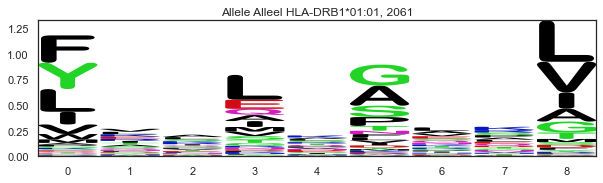

In [104]:
sns.set_theme(style="white")
make_logo_for_data(df.index.values , f'Alleel {selected_allele}')

In [105]:
df = train_repr_df.drop(columns=['allele'])

In [106]:
df

,0,1,2,3,4,5,6,7,8,9,...,1947,1948,1949,1950,1951,1952,1953,1954,1955,1956
core_peptide,,,,,,,,,,,,,,,,,,,,,
YTGEDVTPQ,NaN,-28.082768,NaN,NaN,-32.544429,NaN,NaN,NaN,NaN,NaN,...,NaN,-31.602557,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FKHLKESHL,NaN,-26.181718,NaN,NaN,-34.500060,NaN,NaN,NaN,NaN,NaN,...,NaN,-30.374081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LRQGMFAQL,NaN,-23.578851,NaN,NaN,-30.077439,NaN,NaN,NaN,NaN,NaN,...,NaN,-28.051903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MSGSEVLI,NaN,NaN,NaN,-25.821705,NaN,-25.221291,NaN,-27.407973,NaN,-27.319548,...,-30.217533,NaN,-27.549887,-25.877257,NaN,NaN,NaN,NaN,NaN,NaN
YFPEYAEKI,NaN,-29.411741,NaN,NaN,-36.047018,NaN,NaN,NaN,NaN,NaN,...,NaN,-34.555842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IFEISYF,NaN,NaN,-18.027854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-27.04818,NaN
LLAMAV,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-15.766067,NaN,-14.153322
FHETLD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-23.632046,NaN,-23.229278


D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:654: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


ValueError: The condensed distance matrix must contain only finite values.

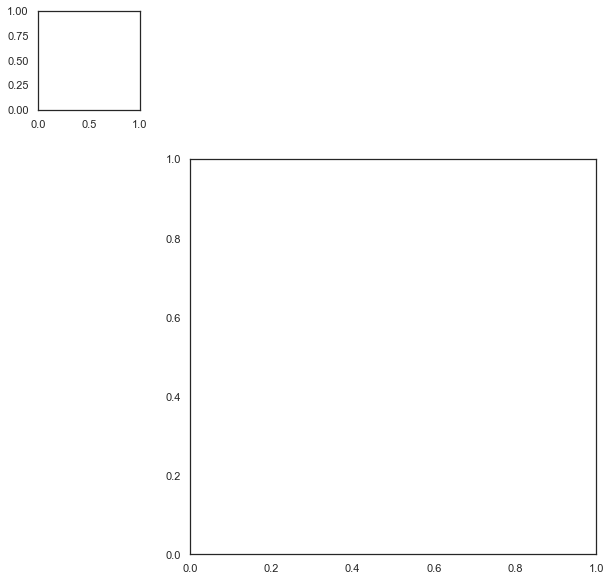

In [107]:
import seaborn as sns
sns.clustermap(df.values)

In [32]:
X = df.drop(columns=['allele', 'peptide'], errors='ignore').values

print(f"Shape of data {X.shape}")

Shape of data (4532, 606)


In [33]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

[]

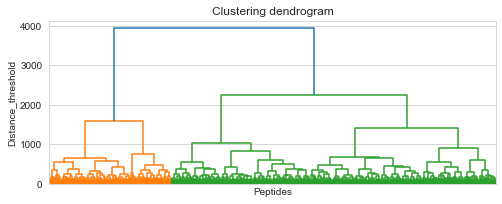

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Peptides')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [35]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=1000
)
model.fit(X)

AgglomerativeClustering(distance_threshold=1000, n_clusters=None)

In [36]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
unique_labels_counts

4    1139
2     909
3     823
0     744
5     499
1     418
dtype: int64

In [37]:
df['label'] = model.labels_

In [38]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [39]:
unique_labels = df['label'].unique()

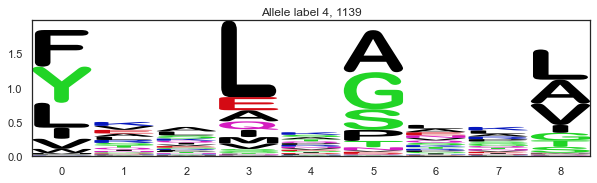

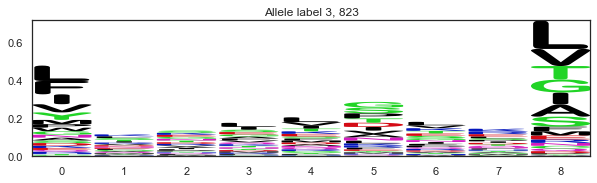

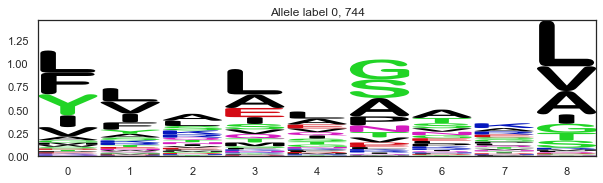

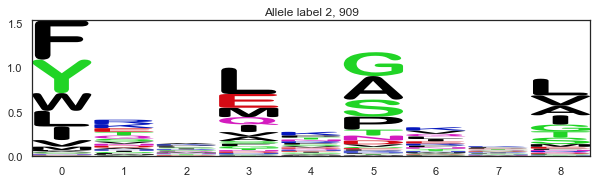

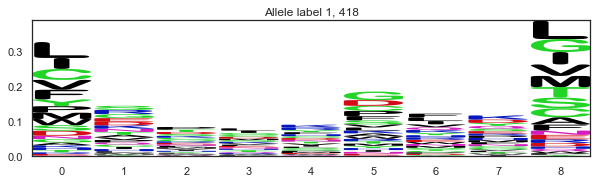

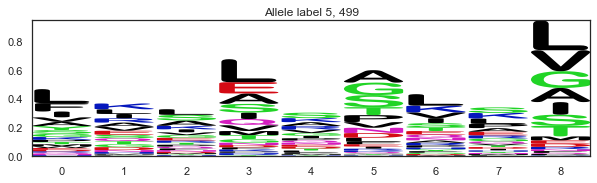

In [40]:
import logomaker

for label in unique_labels:
    target_df = df[df['label'] == label]
    make_logo_for_data(target_df.index.values, f"label {label}")

# Alleles motifs

In [41]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")


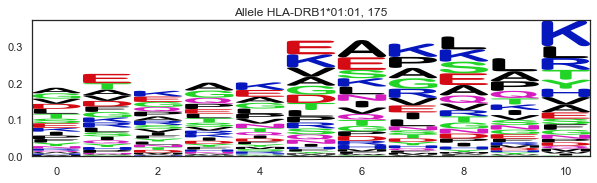

In [44]:
import logomaker
for allele_name in ALLELES:
    binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][11]
    make_logo_for_data(binders_array, allele_name)



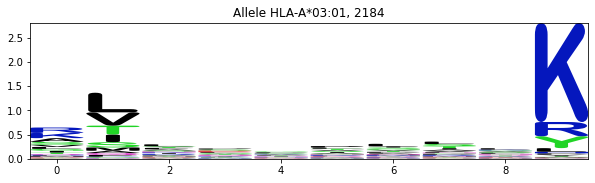

In [64]:
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][10]
matrix = logomaker.alignment_to_matrix(binders_array)
make_logo_for_data(binders_array, allele_name)


In [65]:
df = pd.DataFrame({'peptide': binders_array})
df['pre-last'] = df['peptide'].str[-2]
df['last'] = df['peptide'].str[-1]


In [66]:
df['last'].value_counts()

K    1606
R     230
Y     192
L      58
H      25
F      19
V      13
I      12
A       8
T       8
D       3
M       3
N       2
S       2
Q       1
E       1
P       1
Name: last, dtype: int64

In [67]:
df['pre-last'].value_counts()

L    288
K    165
G    156
A    149
S    146
P    137
F    133
N    132
Y    125
Q    116
T    104
V     99
R     97
E     97
I     57
H     50
D     47
M     45
W     26
C     15
Name: pre-last, dtype: int64

In [70]:
result_df = df[df['peptide'].str[-2] == 'R']

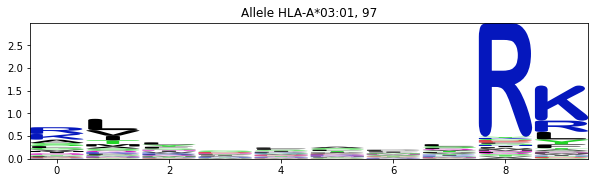

In [71]:
make_logo_for_data(result_df['peptide'].values, allele_name)


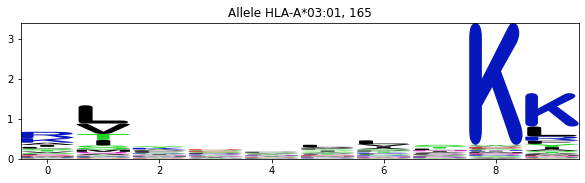

In [72]:
result_df = df[df['peptide'].str[-2] == 'K']
make_logo_for_data(result_df['peptide'].values, allele_name)


In [76]:
result_df = df[(df['peptide'].str[-2] == 'R') & (~df['peptide'].str[-1].isin(['R', 'K'])) ]

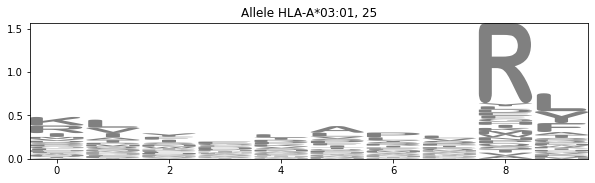

In [77]:
make_logo_for_data(result_df['peptide'].values, allele_name)


In [78]:
result_df = df[(df['peptide'].str[-2] == 'K') & (~df['peptide'].str[-1].isin(['R', 'K'])) ]

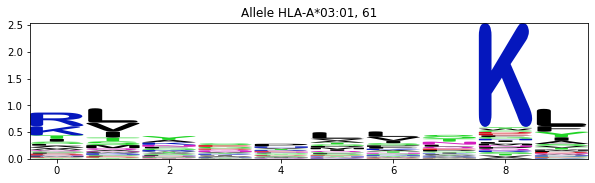

In [79]:
make_logo_for_data(result_df['peptide'].values, allele_name)


Text(0.5, 1.0, 'Allele HLA-A*01:01')

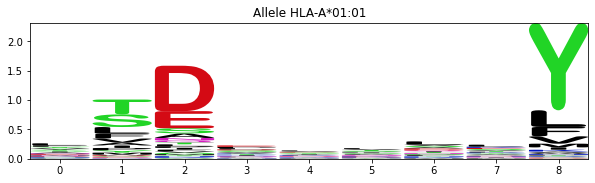

In [35]:
import logomaker
allele_name = 'HLA-A*01:01'
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][9]
matrix = logomaker.alignment_to_matrix(binders_array)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
ww_logo.ax.set_title(f"Allele {allele_name}")

# Some old analysis (just for history)

## Old embedding calculation

In [61]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

NameError: name 'selected_model_run' is not defined

In [13]:
model_bw = per_name_binding_model[mixed_model_bw]
model_bwv = per_name_binding_model[mixed_model_bwv]
model_v = per_name_binding_model[mixed_model_v]


In [17]:
%%time
print("Train")

train_peptides_repr_data_b_model_bw, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model_bw, set(train_peptides_b), paths_df=df_bw_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_bw['peptide'] = train_peptides_repr_data_b_model_bw.index.values
save_embeddingds(train_peptides_repr_data_b_model_bw, model_bw, 'train')

train_peptides_repr_data_b_model_bwv, _, _, _ = \
    get_model_representation(model_bwv, set(train_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_bwv['peptide'] = train_peptides_repr_data_b_model_bwv.index.values
save_embeddingds(train_peptides_repr_data_b_model_bwv, model_bwv, 'train')



train_peptides_repr_data_b_model_v,  _, _, _ = \
    get_model_representation(model_v, set(train_peptides_b), paths_df=df_v_paths, edge_value="log_probability", top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_v['peptide'] = train_peptides_repr_data_b_model_v.index.values
save_embeddingds(train_peptides_repr_data_b_model_v, model_v, 'train')


print("Test")
test_peptides_repr_data_b_model_bw,  _, _, _= \
    get_model_representation(model_bw, set(test_peptides_b), paths_df=df_bw_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name
test_peptides_repr_data_b_model_bw['peptide'] = test_peptides_repr_data_b_model_bw.index.values
save_embeddingds(test_peptides_repr_data_b_model_bw, model_bw, 'test')


test_peptides_repr_data_b_model_bwv,  _, _, _ = \
    get_model_representation(model_bwv, set(test_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name
test_peptides_repr_data_b_model_bwv['peptide'] = test_peptides_repr_data_b_model_bwv.index.values
save_embeddingds(test_peptides_repr_data_b_model_bwv, model_bwv, 'test')


test_peptides_repr_data_b_model_v,  _, _, _= \
    get_model_representation(model_v, set(test_peptides_b), paths_df=df_v_paths, edge_value="log_probability",  top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name    
test_peptides_repr_data_b_model_v['peptide'] = test_peptides_repr_data_b_model_v.index.values
save_embeddingds(test_peptides_repr_data_b_model_v, model_v, 'test')



per_name_representation_train["bw"] = {"db": train_peptides_repr_data_b_model_bw  }
per_name_representation_train["bwv"] = {"db": train_peptides_repr_data_b_model_bwv  }
per_name_representation_train["v"] = {"db": train_peptides_repr_data_b_model_v  }
per_name_representation_test["bw"] = {"db": test_peptides_repr_data_b_model_bw  }
per_name_representation_test["bwv"] = {"db": test_peptides_repr_data_b_model_bwv  }
per_name_representation_test["v"] = {"db": test_peptides_repr_data_b_model_v  }


Train
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 1533/1533 [01:40<00:00, 15.22it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 1593/1593 [01:55<00:00, 13.77it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 2000/2000 [02:21<00:00, 14.09it/s]


... (3 outputs left out)

100%|█████████████████████████████████████████████████████████████████████| 1593/1593 [00:28<00:00, 55.95it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 2000/2000 [00:38<00:00, 51.39it/s]


Finished
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Wall time: 9min 52s


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

## Heatmap

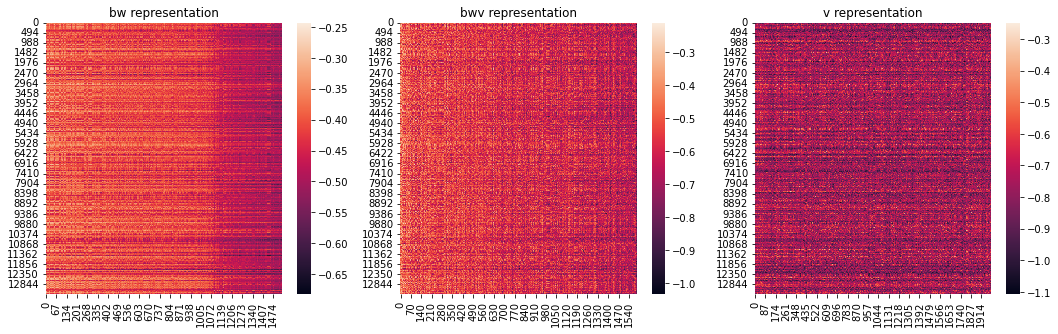

In [19]:
fig, axes = plt.subplots(nrows=1, ncols= 3, figsize=(18, 5))

representations= ['bw', 'bwv', 'v']

for i,representation in enumerate(representations):
    data = per_name_representation_train[representation]['db'].drop(columns=["allele", "peptide"])
    ax = sns.heatmap(data=data.values, ax=axes[i])
    ax.set_title(f"{representation} representation")
    plt.tight_layout



In [ ]:
df_v_paths

In [ ]:
data.describe()

,0,1,2,3,4,5,6,7,8,9,...,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
count,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,...,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000
mean,-1.067070,-1.058302,-1.065228,-1.050695,-1.064849,-1.059642,-1.085568,-1.063796,-1.074783,-1.072680,...,-1.060848,-1.077650,-1.077042,-1.023197,-1.076935,-1.095326,-1.092772,-1.134132,-1.070400,-1.084842
std,0.171402,0.182489,0.180374,0.171565,0.167488,0.176177,0.172055,0.179105,0.178771,0.172112,...,0.166851,0.167418,0.168829,0.172461,0.172579,0.173150,0.166933,0.154954,0.166417,0.167511
min,-1.446166,-1.444599,-1.444119,-1.452129,-1.446139,-1.442628,-1.452834,-1.446566,-1.456492,-1.447897,...,-1.529080,-1.454239,-1.460754,-1.527722,-1.462702,-1.451177,-1.452313,-1.457219,-1.529956,-1.460165
25%,-1.190884,-1.190428,-1.191343,-1.184345,-1.190542,-1.190154,-1.201886,-1.192240,-1.202450,-1.193571,...,-1.168371,-1.200345,-1.206049,-1.152281,-1.205022,-1.208356,-1.208730,-1.241343,-1.179316,-1.207329
50%,-1.072764,-1.066179,-1.068204,-1.060093,-1.069055,-1.070125,-1.083172,-1.068235,-1.079435,-1.076180,...,-1.052371,-1.080604,-1.085074,-1.032875,-1.082720,-1.092043,-1.095000,-1.139945,-1.066710,-1.087174
75%,-0.948327,-0.936270,-0.938280,-0.937860,-0.948465,-0.943987,-0.957934,-0.939732,-0.948956,-0.955498,...,-0.936163,-0.959323,-0.963852,-0.913754,-0.960770,-0.966146,-0.974065,-1.033306,-0.952474,-0.966990
max,-0.383194,-0.291527,-0.360350,-0.405895,-0.377822,-0.335044,-0.411205,-0.401107,-0.351187,-0.254972,...,-0.336242,-0.426618,-0.418639,-0.402584,-0.356660,-0.431028,-0.381794,-0.475942,-0.468970,-0.371424


## Count Peptides per paths (Not valid for non-sparse data)

In [35]:
df = per_name_representation_train["v"]["db"]
max([len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

20

<AxesSubplot:>

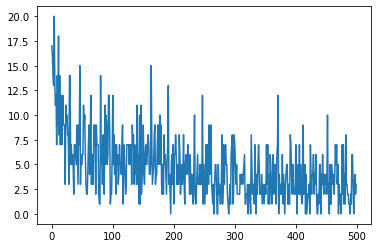

In [36]:
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

<AxesSubplot:>

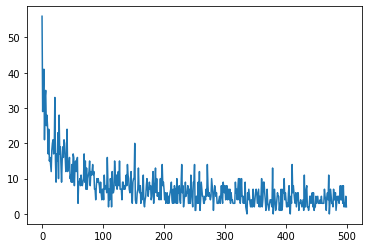

In [37]:
df = per_name_representation_train["bwv"]["db"]
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])


## Plot motifs for top paths

In [77]:
import logomaker
import matplotlib.pyplot as plt
from collections import defaultdict
from mhcgnomes import parse

def check_path_motif(top_paths, representation, length=9, start = 0, threshold=-0.4):
    fig,axes = plt.subplots(figsize=(5*top_paths, 3), nrows=2, ncols=top_paths)
    df = representation[representation.index.str.len() == length]
    for i in range(start, top_paths+start):
        print(i, end=" ")
        filtered_df = df[df[i] > threshold].copy()
        filtered_df['allele'] = filtered_df['allele'].apply(lambda x: parse(x).compact_string())
        counts = defaultdict(int)
        counts.update(dict(filtered_df['allele'].value_counts()))
        # print(counts)
        # print(filtered_df['allele'].value_counts())
        binders_array = filtered_df.index.values
        matrix = logomaker.alignment_to_matrix(binders_array)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[0, i-start])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        compact_alleles = [parse(allele).compact_string() for allele, cnt in sorted(counts.items())]
        counts_list = [i for allele, i in sorted(counts.items())]
        ww_logo.ax.set_title(f"Path {i}, \n {compact_alleles} \n {counts_list}")
        # filtered_df = filtered_df.sort_values(by=path_index)
        filtered_df = filtered_df.sort_values(by='allele')
        sns.boxplot(data=filtered_df, y=filtered_df[i], x='allele', ax=axes[1, i-start])

    print()



0 1 2 3 4 


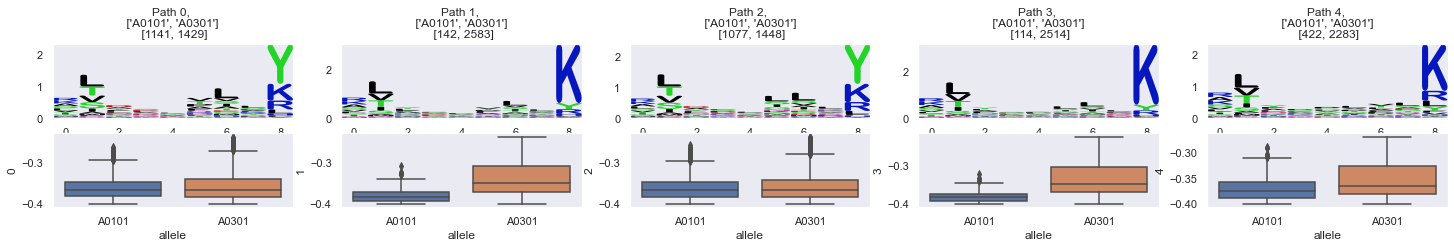

In [78]:
check_path_motif(5, per_name_representation_train["bwv"]["db"], start=0)


0 1 2 3 4 


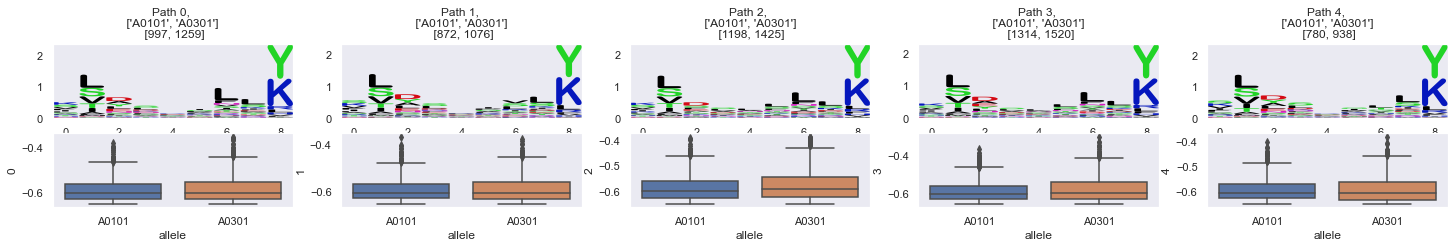

In [84]:
check_path_motif(5, per_name_representation_train["v"]["db"],start=0, threshold=-0.65)

In [87]:
per_name_representation_train["v"]["db"].loc[:,:10]

,0,1,2,3,4,5,6,7,8,9,10
FLNPLISKY,-0.583338,-0.499502,-0.647481,-0.575670,-0.584794,-0.573598,-0.669384,-0.516937,-0.680696,-0.668799,-0.565216
KSGPVIAKR,-0.758313,-0.760343,-0.763332,-0.832571,-0.759769,-0.710017,-0.844359,-0.775959,-0.758595,-0.677126,-0.766933
KSPSEPLIPK,-0.475953,-0.568151,-0.592640,-0.585523,-0.567576,-0.492600,-0.565322,-0.521948,-0.448726,-0.716066,-0.686409
NFLRSIAMLK,-0.734659,-0.736689,-0.892025,-0.808917,-0.736114,-0.743825,-0.820704,-0.713631,-0.808977,-0.640324,-0.895626
AYDPTAPTL,-0.857848,-0.859878,-0.918900,-0.917718,-0.859303,-0.820858,-0.929505,-0.781309,-0.932166,-0.637254,-0.922502
...,...,...,...,...,...,...,...,...,...,...,...
KVYPKAVER,-0.712731,-0.630197,-0.858706,-0.778535,-0.714186,-0.667054,-0.784389,-0.653712,-0.713013,-0.679135,-0.777744
RILLPIVQK,-0.626883,-0.544349,-0.810727,-0.727618,-0.628338,-0.642500,-0.712928,-0.591861,-0.591281,-0.722848,-0.729764
IPDQVIRVF,-0.795142,-0.719681,-0.855073,-0.853891,-0.793273,-0.781202,-0.881187,-0.767336,-0.862664,-0.811152,-0.781184
LVYIFEPEK,-0.801877,-0.803907,-0.820486,-0.740314,-0.803333,-0.807437,-0.810405,-0.742859,-0.766275,-0.629544,-0.824087


0 1 2 3 4 


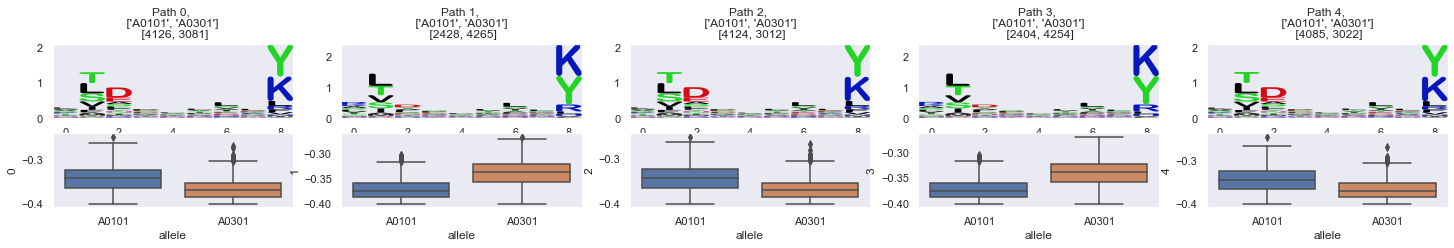

In [83]:
check_path_motif(5, per_name_representation_train["bw"]["db"])

## Compare paths

In [38]:
df = per_name_representation_train["v"]["db"]

In [39]:
from collections import defaultdict
from tqdm import tqdm
per_allele_per_path_cnt = dict()
observed_peptides = set()
paths_cnt = len(df.columns) - 1
for allele_name in selected_alleles:
    per_allele_per_path_cnt[allele_name] = defaultdict(int)
    for path_index in tqdm(range(paths_cnt)):
        filtered_df = df.loc[(df[path_index] != -55) & (df['allele'] == allele_name)]
        for peptide in filtered_df.index:
            if peptide not in observed_peptides:
                per_allele_per_path_cnt[allele_name][path_index] += 1
                observed_peptides.add(peptide)


100%|██████████| 500/500 [00:00<00:00, 661.37it/s]


## Compare peptides per paths for alleles (Not valid for non-sparse data)

In [40]:
from mhcgnomes import parse
cnt_df = pd.DataFrame(index=np.arange(paths_cnt))


for allele_name in selected_alleles:
    allele_counts = np.zeros(shape=(paths_cnt))
    for path_index in range(paths_cnt):
        allele_counts[path_index] = per_allele_per_path_cnt[allele_name][path_index]
    cnt_df[f'allele_{parse(allele_name).compact_string()}_cnt'] =  allele_counts

<AxesSubplot:xlabel='paths', ylabel='cnt of new peptides'>

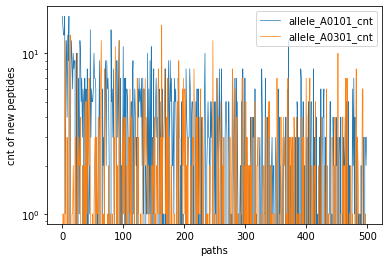

In [41]:
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.plot(ax= ax, xlabel='paths', ylabel='cnt of new peptides', lw=0.7, alpha=1, logy=True)


<AxesSubplot:xlabel='paths', ylabel='cumulative summ of peptides'>

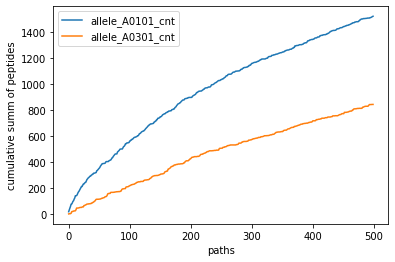

In [42]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.cumsum().plot(ax= ax, xlabel='paths', ylabel='cumulative summ of peptides',)

In [233]:
cnt_df.cumsum().loc[7500]

allele_A0101_cnt    4445.0
allele_A0301_cnt    3742.0
Name: 7500, dtype: float64

<AxesSubplot:>

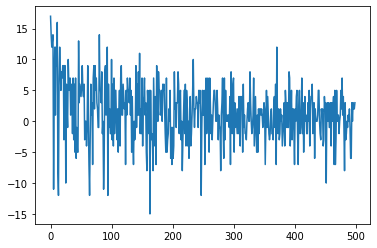

In [43]:
(cnt_df['allele_A0101_cnt'] - cnt_df['allele_A0301_cnt']).plot()

In [45]:
from collections import defaultdict

per_allele_path_counts = dict()
for allele_name in selected_alleles:
    per_allele_path_counts[allele_name] = defaultdict(int)

paths_cnt = len(df.columns) - 1
for path_index in range(paths_cnt):
    counts = df[df[path_index] != -55]['allele'].value_counts()
    for allele_name in selected_alleles:
        if allele_name in counts and counts[allele_name] != 0:
            per_allele_path_counts[allele_name][path_index] = counts[allele_name]

In [46]:
max(per_allele_path_counts[ALLELES[0]].values())

17

## How many peptides we represent with selected TOP

In [47]:
df.loc[(df.drop(columns=['allele']) != -55).any(axis=1)]['allele'].value_counts().sort_values()

HLA-A*03:01     843
HLA-A*01:01    1522
Name: allele, dtype: int64

In [151]:
selected_alleles

['HLA-A*01:01', 'HLA-A*03:01']

In [152]:
path_indexes = [i for i in range(paths_cnt)]
per_allele_df = dict()
for allele_name in selected_alleles:
    allele_cnt = [per_allele_path_counts[allele_name][i] if i in per_allele_path_counts[allele_name] else 0 for i in path_indexes]
    allele_df = pd.DataFrame({"path": path_indexes, "cnt": allele_cnt, "allele": allele_name})
    per_allele_df[allele_name] = allele_df

for allele_name in selected_alleles:
    per_allele_df[allele_name]['diff'] = per_allele_df[selected_alleles[1]]['cnt'] - per_allele_df[selected_alleles[0]]['cnt']

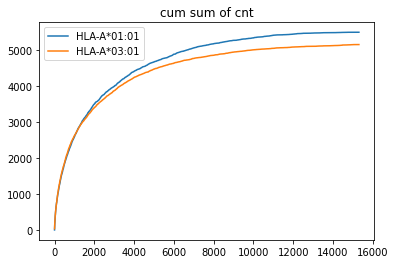

In [153]:


for allele_name in selected_alleles:
    per_allele_df[allele_name]['cnt'].cumsum().plot(ax= ax, x='path', title="cum sum of cnt", legend=True)
ax.legend(selected_alleles);

allele
HLA-A*03:01    4522
HLA-A*01:01    4720
Name: cnt, dtype: int64


<AxesSubplot:xlabel='path', ylabel='cnt'>

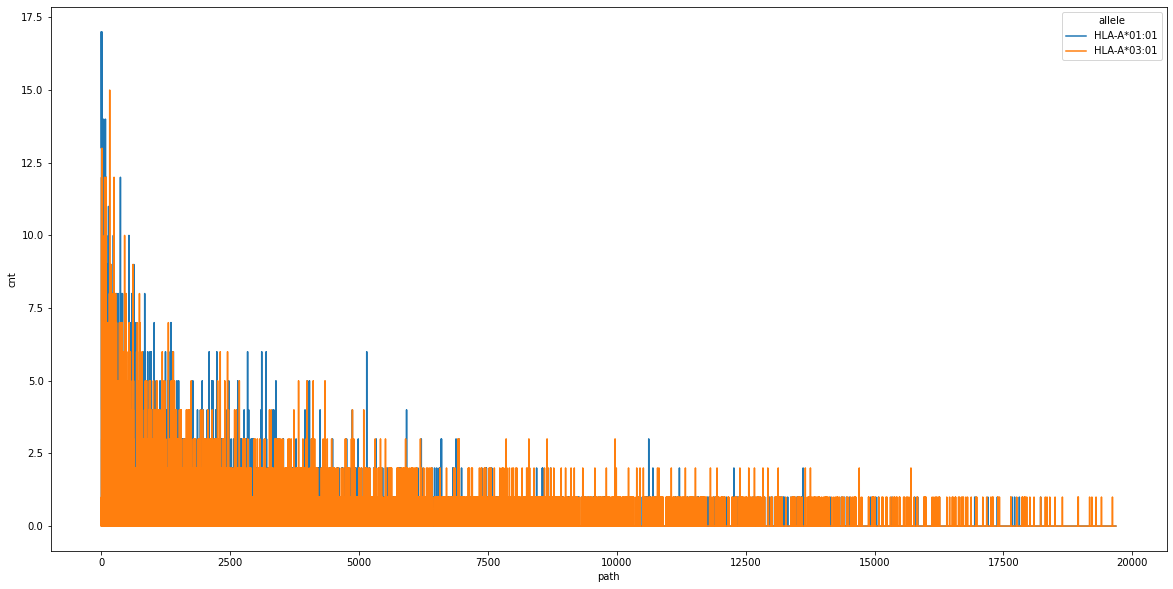

In [143]:

# sns.set_color_codes("pastel")
plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True)
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True)
print(df_to_plot.groupby('allele').sum()['cnt'].sort_values())

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')

In [237]:
for allele_name in selected_alleles:

    per_allele_df[allele_name] =  per_allele_df[allele_name].sort_values(by='diff').reset_index(drop=True)

    per_allele_df[allele_name]['prev_path'] = per_allele_df[allele_name]['path'].values
    per_allele_df[allele_name]['path'] = per_allele_df[allele_name].index.values



[]

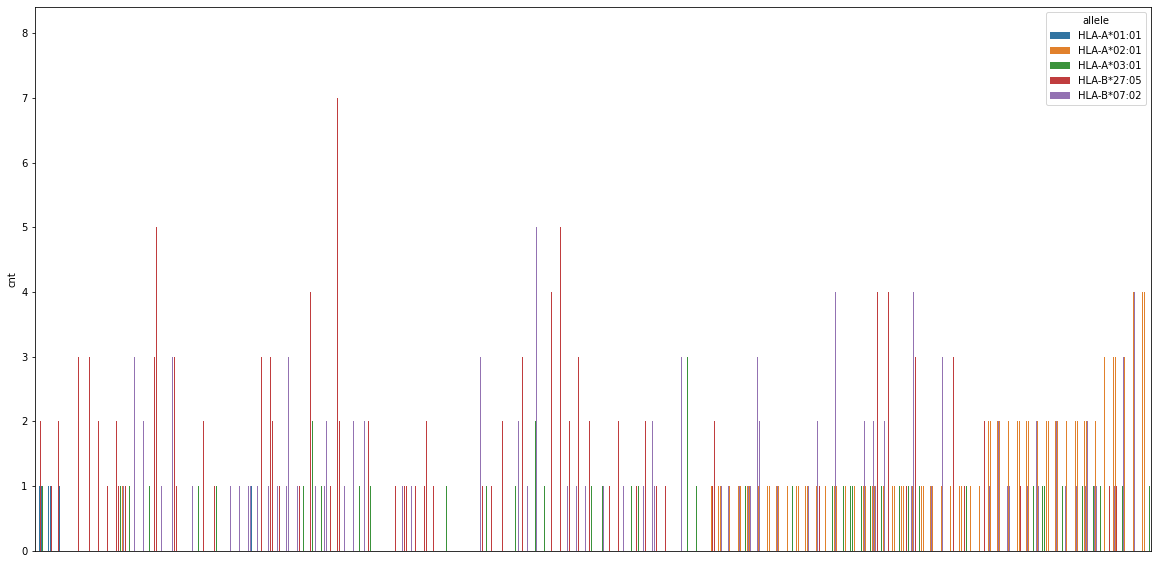

In [238]:

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True).sort_values(by='diff')
ax = sns.barplot(data=df_to_plot, x='path', y='cnt', hue='allele')
ax.set_xlabel('')
ax.set_xticks([])

<AxesSubplot:xlabel='path', ylabel='cnt'>

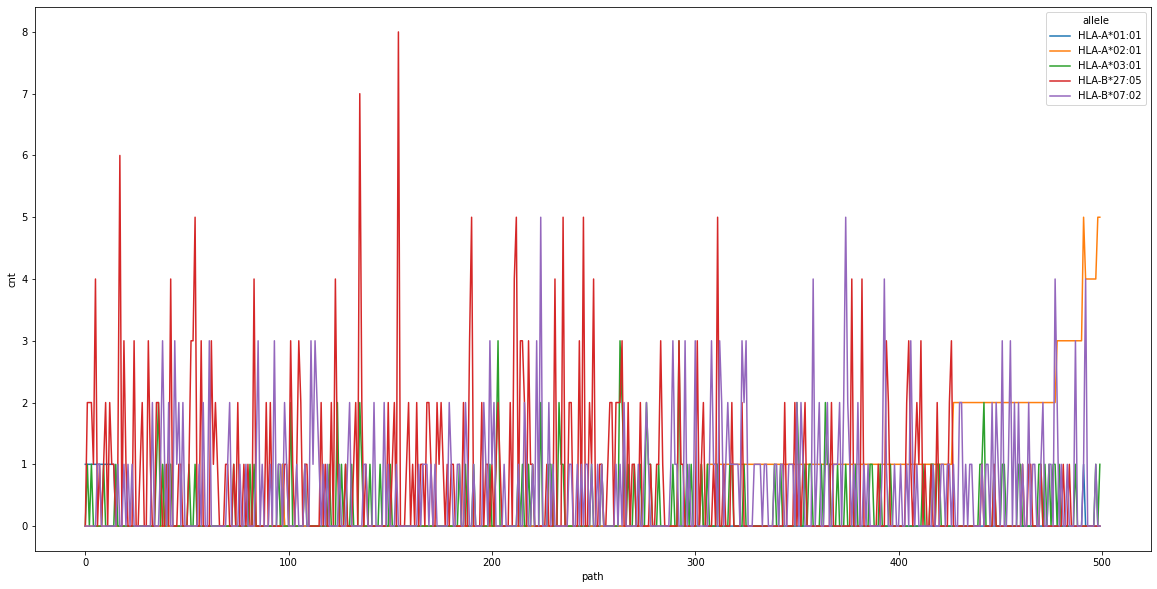

In [239]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')



In [36]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,label
PVSMTYLYNK,-0.767756,-1.088749,-1.088269,-1.136451,-1.110482,-1.126951,-0.866452,-0.985360,-0.735749,-0.874844,...,-1.145076,-1.230186,-1.147024,-0.874245,-1.095748,-1.457219,-1.120143,-1.239554,HLA-A*03:01,1
NYDLALKYF,-1.133209,-0.807913,-0.938645,-0.989824,-1.055381,-0.980324,-1.221345,-1.072828,-1.225003,-1.003204,...,-0.936420,-0.907656,-1.070104,-1.219688,-1.100022,-1.130287,-1.023211,-1.052718,HLA-A*01:01,0
TLKSFTVEK,-1.045980,-1.164910,-1.164430,-1.309880,-1.180526,-1.442628,-1.052648,-1.166878,-1.043307,-1.047711,...,-1.336272,-1.034953,-1.058531,-1.171488,-1.067980,-1.081329,-1.393245,-1.207510,HLA-A*03:01,1
AIFTDASTV,-1.062561,-0.941709,-0.941229,-0.655181,-0.822113,-0.645681,-1.069229,-1.062961,-1.006282,-0.945006,...,-0.834980,-0.810637,-0.835843,-0.821074,-0.946041,-1.074098,-0.576180,-0.962399,HLA-A*02:01,2
KLEYLAPSY,-1.049917,-0.929065,-0.928585,-0.919620,-0.980604,-1.052369,-0.925646,-1.050318,-1.060243,-0.932363,...,-1.184716,-0.893841,-0.919782,-1.054928,-1.011185,-1.143730,-1.156217,-1.098082,HLA-A*01:01,0
